# Customer Cohort & Retention Analysis(SQL +Python)

## 1. Project Objective

This project analyzes customer purchasing activity using cohort analysis. Customers are grouped by the month of their first purchase, and their monthly active retention rates are tracked over the following 12 months.

The analysis aims to answer three business questions:

1. **Overall retention pattern:** How does monthly active retention change after customers make their first purchase?
2. **Cohort-level differences:** How does monthly active retention vary across customer acquisition cohorts?
3. **Change over acquisition periods:** Do cohorts acquired in later months show consistently higher retention rates?

The objective is to identify descriptive patterns in customer purchasing behavior and assess whether the available data provides evidence of consistent retention improvement across cohorts.

In [1]:
import duckdb

file_path = "/kaggle/input/datasets/vivek468/superstore-dataset-final/Sample - Superstore.csv"

duckdb.sql(f"""
SELECT *
FROM read_csv(
    '{file_path}',
    encoding='utf-8',
    ignore_errors=true
)
LIMIT 10
""")


┌────────┬────────────────┬────────────┬────────────┬────────────────┬─────────────┬─────────────────┬───────────┬───────────────┬─────────────────┬────────────┬─────────────┬─────────┬─────────────────┬─────────────────┬──────────────┬──────────────────────────────────────────────────────────────────┬──────────┬──────────┬──────────┬──────────┐
│ Row ID │    Order ID    │ Order Date │ Ship Date  │   Ship Mode    │ Customer ID │  Customer Name  │  Segment  │    Country    │      City       │   State    │ Postal Code │ Region  │   Product ID    │    Category     │ Sub-Category │                           Product Name                           │  Sales   │ Quantity │ Discount │  Profit  │
│ int64  │    varchar     │    date    │    date    │    varchar     │   varchar   │     varchar     │  varchar  │    varchar    │     varchar     │  varchar   │   varchar   │ varchar │     varchar     │     varchar     │   varchar    │                             varchar                              │ 

In [2]:
duckdb.sql(f"""
CREATE OR REPLACE TABLE orders AS
SELECT *
FROM read_csv(
    '{file_path}',
    encoding='utf-8',
    ignore_errors=true
)
""")

In [3]:
df = duckdb.sql("""

WITH customer_first_purchase AS (
SELECT
        "Customer ID",
        MIN("Order Date") AS "First Purchase Date"
FROM orders
GROUP BY "Customer ID"
    ),
    
customer_cohort AS (
SELECT
        "Customer ID",
        "First Purchase Date",
        DATE_TRUNC('MONTH',"First Purchase Date")AS "Cohort Month"
FROM customer_first_purchase
    ),

orders_with_cohort AS (
SELECT
    orders."Customer ID",
    orders."Order Date",
    customer_cohort."Cohort Month"
FROM orders
LEFT JOIN customer_cohort
    ON orders."Customer ID" = customer_cohort."Customer ID"
    ),

order_month AS (
SELECT
    "Customer ID",
    DATE_TRUNC('MONTH',"Order Date")AS "Order Month",
    "Cohort Month"
FROM orders_with_cohort
    ),

month_number AS (
SELECT
    "Customer ID",
    "Order Month",
    "Cohort Month",
     DATE_DIFF('MONTH',"Cohort Month","Order Month") AS "Month Number"
FROM order_month
    ),

cohort_list AS (
    SELECT DISTINCT
        "Cohort Month"
    FROM month_number
),

month_list AS (
    SELECT
        RANGE AS "Month Number"
    FROM RANGE(
        (SELECT MAX("Month Number") + 1 FROM month_number)
    )
),

cohort_grid AS (
    SELECT
        cohort_list."Cohort Month",
        month_list."Month Number"
    FROM cohort_list 
    CROSS JOIN month_list 
),

observed_grid AS (
    SELECT
        cohort_grid."Cohort Month",
        cohort_grid."Month Number"
    FROM cohort_grid 
    WHERE DATE_ADD(
        cohort_grid."Cohort Month",
        INTERVAL (cohort_grid."Month Number") MONTH
    ) <= (
        SELECT MAX("Order Date")
        FROM orders
    )
),

active_customers AS (
    SELECT
        observed_grid."Cohort Month",
        observed_grid."Month Number",
        COUNT(DISTINCT month_number."Customer ID") AS "Active Customers"
    FROM observed_grid 
    LEFT JOIN month_number 
        ON observed_grid."Cohort Month" = month_number."Cohort Month"
        AND observed_grid."Month Number" = month_number."Month Number"
    GROUP BY
        observed_grid."Cohort Month",
        observed_grid."Month Number"
),

initial_customers AS (
SELECT
     "Cohort Month",
     "Month Number",
     "Active Customers",
     MAX(
            CASE
                WHEN "Month Number" = 0
                THEN "Active Customers"
            END
        ) OVER (
            PARTITION BY "Cohort Month"
        ) AS "Initial Customers"
FROM active_customers
     ),

customer_retention AS (
SELECT
      "Cohort Month",
      "Month Number",
      "Active Customers",
      "Initial Customers",
      "Active Customers"/"Initial Customers" AS "Retention Rate"
FROM initial_customers
      )

SELECT *
FROM customer_retention
ORDER BY "Cohort Month", "Month Number"

""").df()

## 2. Data Preparation and Metric Definition

The analysis uses the Superstore dataset. SQL was used to identify each customer's first purchase month, assign customers to acquisition cohorts, calculate the number of months since the cohort's first purchase, and count distinct active customers in each cohort-month combination.

A complete cohort-month grid was created for observable periods. Combinations with no active customers were retained and assigned a retention rate of zero, while periods beyond the dataset's observation window were excluded.

Here, an active customer is a customer who placed at least one order during the relevant month. Month 0 represents the month of the first purchase, so its retention rate is 100% by definition.

This metric measures monthly purchasing activity relative to the initial cohort size. It does not measure continuous customer retention or cumulative repeat-purchase rates. Customers who do not purchase in one month may return in a later month.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df.head()

,Cohort Month,Month Number,Active Customers,Initial Customers,Retention Rate
0,2014-01-01,0,32,32,1.00000
1,2014-01-01,1,3,32,0.09375
2,2014-01-01,2,0,32,0.00000
3,2014-01-01,3,2,32,0.06250
4,2014-01-01,4,2,32,0.06250


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1123 entries, 0 to 1122
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Cohort Month       1123 non-null   datetime64[us]
 1   Month Number       1123 non-null   int64         
 2   Active Customers   1123 non-null   int64         
 3   Initial Customers  1123 non-null   int64         
 4   Retention Rate     1123 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(3)
memory usage: 44.0 KB


In [6]:
df.describe()

,Cohort Month,Month Number,Active Customers,Initial Customers,Retention Rate
count,1123,1123.000000,1123.000000,1123.000000,1123.000000
mean,2015-03-23 00:35:54.229741,16.157614,4.023152,26.650045,0.165446
min,2014-01-01 00:00:00,0.000000,0.000000,1.000000,0.000000
25%,2014-07-01 00:00:00,6.500000,1.000000,8.000000,0.045455
50%,2015-02-01 00:00:00,14.000000,2.000000,17.000000,0.125000
75%,2015-11-01 00:00:00,24.000000,5.000000,48.000000,0.188988
max,2017-11-01 00:00:00,47.000000,68.000000,68.000000,1.000000
std,NaN,11.434347,6.115160,21.864831,0.208515


In [7]:
cohort_size = (
    df[df["Month Number"] == 0]
    [["Cohort Month", "Initial Customers"]]
    .drop_duplicates()
    .sort_values("Cohort Month")
    .reset_index(drop=True)
)

cohort_size

,Cohort Month,Initial Customers
0,2014-01-01,32
1,2014-02-01,22
2,2014-03-01,63
3,2014-04-01,55
4,2014-05-01,54
5,2014-06-01,46
6,2014-07-01,45
7,2014-08-01,48
8,2014-09-01,68
9,2014-10-01,43


In [8]:
cohort_observation = (
    df.groupby("Cohort Month")["Month Number"]
    .max()
    .reset_index(name="Max Observed Month")
)

cohort_profile = cohort_size.merge(
    cohort_observation,
    on="Cohort Month",
    how="left"
)

cohort_profile

,Cohort Month,Initial Customers,Max Observed Month
0,2014-01-01,32,47
1,2014-02-01,22,46
2,2014-03-01,63,45
3,2014-04-01,55,44
4,2014-05-01,54,43
5,2014-06-01,46,42
6,2014-07-01,45,41
7,2014-08-01,48,40
8,2014-09-01,68,39
9,2014-10-01,43,38


In [9]:
eligible_cohorts = cohort_profile.loc[
    (cohort_profile["Initial Customers"] >= 30)
    & (cohort_profile["Max Observed Month"] >= 12),
    "Cohort Month"
]

analysis_df = df.loc[
    df["Cohort Month"].isin(eligible_cohorts)
    & df["Month Number"].between(0, 12)
].copy()

analysis_df

,Cohort Month,Month Number,Active Customers,Initial Customers,Retention Rate
0,2014-01-01,0,32,32,1.00000
1,2014-01-01,1,3,32,0.09375
2,2014-01-01,2,0,32,0.00000
3,2014-01-01,3,2,32,0.06250
4,2014-01-01,4,2,32,0.06250
...,...,...,...,...,...
481,2014-12-01,8,5,50,0.10000
482,2014-12-01,9,9,50,0.18000
483,2014-12-01,10,5,50,0.10000
484,2014-12-01,11,7,50,0.14000


## 3. Cohort Selection

To improve comparability across cohorts, two eligibility criteria were applied:

- Each cohort must contain at least 30 initial customers.
- Each cohort must have at least 12 observable months after its initial purchase month.

The analysis then retains Month 0 through Month 12 for each eligible cohort.

After filtering, 11 cohorts acquired between January and December 2014 were included, excluding February 2014 because it had only 24 initial customers. The selected cohorts contain 571 initial customers in total and 143 cohort-month observations.

This selection provides a consistent 13-month observation window and reduces the influence of very small cohorts. However, it also limits the analysis to a selected group of 2014 cohorts; the results should not automatically be generalized to every customer or acquisition period in the dataset.

In [10]:
overall_retention = (
    analysis_df.groupby("Month Number", as_index=False)
    .agg(Active_Customers=("Active Customers", "sum"))
)

total_initial_customers = (
    analysis_df.loc[
        analysis_df["Month Number"] == 0,
        "Initial Customers"
    ].sum()
)

overall_retention["Retention Rate"] = (
    overall_retention["Active_Customers"]
    / total_initial_customers
)

display(overall_retention)

,Month Number,Active_Customers,Retention Rate
0,0,564,1.000000
1,1,59,0.104610
2,2,37,0.065603
3,3,50,0.088652
4,4,45,0.079787
5,5,45,0.079787
6,6,58,0.102837
7,7,55,0.097518
8,8,61,0.108156
9,9,42,0.074468


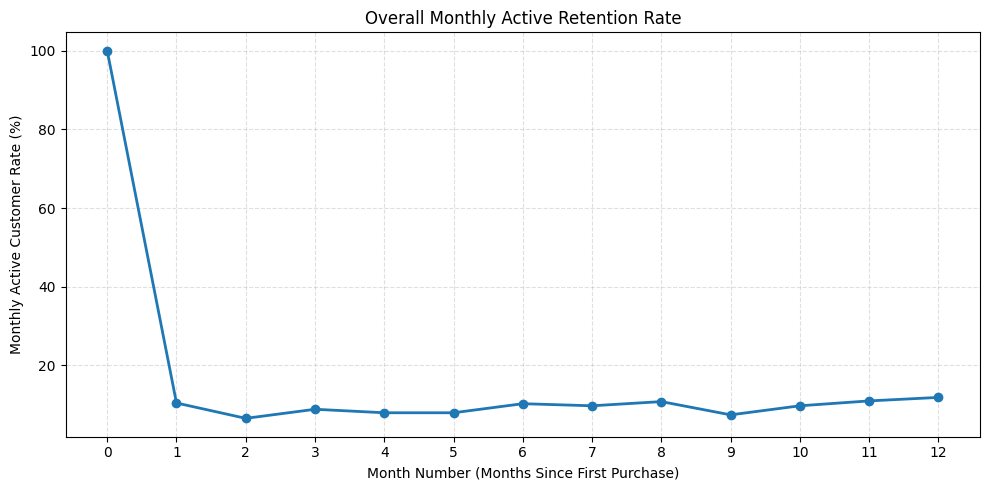

In [11]:
overall_retention = overall_retention.sort_values("Month Number")

plt.figure(figsize=(10, 5))

plt.plot(
    overall_retention["Month Number"],
    overall_retention["Retention Rate"] * 100,
    marker="o",
    linewidth=2
)

plt.title("Overall Monthly Active Retention Rate")
plt.xlabel("Month Number (Months Since First Purchase)")
plt.ylabel("Monthly Active Customer Rate (%)")

plt.xticks(range(13))

plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## 4. Overall Monthly Active Retention Trend

The overall monthly active retention rate shows a sharp decline from Month 0 to Month 1. Month 0 is 100% by definition, whereas approximately 11.0% of the initial customers were active in Month 1.

From Month 1 to Month 12, the rate fluctuates rather than declining continuously. It falls to approximately 6.5% in Month 2, rises to around 10.7% in Month 6, and reaches approximately 11.7% in Month 12.

These results suggest that purchasing activity after the initial purchase is relatively low, but the pattern is not a steady month-by-month decline. Some customers may return after one or more inactive months.

The Month 12 rate should therefore be interpreted as the proportion of the original cohort that was active in Month 12, not the proportion that purchased continuously throughout the entire period.

In [12]:
retention_matrix = analysis_df.pivot(
    index="Cohort Month",
    columns="Month Number",
    values="Retention Rate"
)
retention_matrix = retention_matrix.sort_index()
display(retention_matrix)

Month Number,0,1,2,3,4,5,6,7,8,9,10,11,12
Cohort Month,,,,,,,,,,,,,
2014-01-01,1.0,0.093750,0.000000,0.062500,0.062500,0.000000,0.062500,0.125000,0.156250,0.062500,0.218750,0.156250,0.093750
2014-03-01,1.0,0.063492,0.031746,0.126984,0.111111,0.000000,0.111111,0.063492,0.126984,0.095238,0.015873,0.015873,0.095238
2014-04-01,1.0,0.109091,0.036364,0.072727,0.054545,0.145455,0.109091,0.163636,0.145455,0.018182,0.072727,0.090909,0.145455
2014-05-01,1.0,0.074074,0.092593,0.074074,0.166667,0.037037,0.185185,0.166667,0.074074,0.055556,0.055556,0.111111,0.037037
2014-06-01,1.0,0.021739,0.043478,0.065217,0.043478,0.173913,0.152174,0.021739,0.086957,0.130435,0.065217,0.086957,0.043478
2014-07-01,1.0,0.133333,0.133333,0.000000,0.111111,0.200000,0.044444,0.000000,0.177778,0.044444,0.155556,0.155556,0.111111
2014-08-01,1.0,0.166667,0.041667,0.229167,0.104167,0.062500,0.083333,0.041667,0.083333,0.062500,0.083333,0.125000,0.041667
2014-09-01,1.0,0.132353,0.132353,0.161765,0.014706,0.029412,0.132353,0.147059,0.132353,0.029412,0.088235,0.117647,0.176471
2014-10-01,1.0,0.069767,0.116279,0.023256,0.069767,0.093023,0.116279,0.093023,0.069767,0.093023,0.093023,0.162791,0.093023


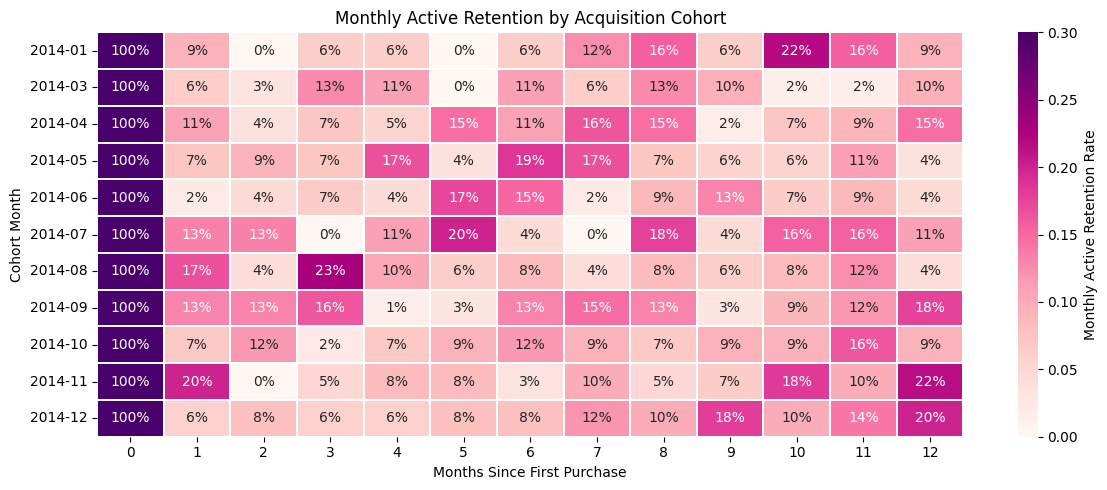

In [13]:
retention_matrix.index = pd.to_datetime(
    retention_matrix.index
).strftime("%Y-%m")

plt.figure(figsize=(12, 5))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt=".0%",
    cmap="RdPu",
    vmin=0,
    vmax=0.3,
    linewidths=0.3,
    linecolor="white",
    cbar_kws={"label": "Monthly Active Retention Rate"}
)

plt.title("Monthly Active Retention by Acquisition Cohort")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Cohort Month")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Monthly Active Retention Across Cohorts

The cohort heatmap reveals substantial variation in monthly active retention across both acquisition cohorts and months since the first purchase.

Some cohort-month combinations show relatively high activity, while others show very low or zero activity. For example, the November 2014 cohort has a Month 1 active retention rate of approximately 24.2%, while some other cohorts have much lower rates in the same month. Several cohorts also experience increases in activity after earlier declines.

These differences indicate that customer purchasing activity is not uniform across cohorts or over time. However, isolated high or low values do not establish that a cohort has fundamentally better or worse long-term retention. The observed differences may also be affected by cohort size and variation in individual purchasing behavior.

Overall, the heatmap is useful for identifying descriptive differences and potential areas for further investigation, but it does not by itself explain why those differences occur.

## 6. Retention Changes Across Acquisition Periods

To assess whether customer retention improved over time, cohorts acquired in different months were compared at the same lifecycle stage.

The Month 1 active retention rate varies considerably across the selected cohorts. For example, it is approximately 9.4% for the January 2014 cohort, 16.3% for the August 2014 cohort, 24.2% for the November 2014 cohort, and 6.1% for the December 2014 cohort.

Although some later cohorts show higher rates than earlier cohorts, the pattern is not consistently upward. The results therefore do not provide clear descriptive evidence of sustained retention improvement across the selected acquisition periods.

This comparison identifies a pattern in the observed data, but it does not establish whether acquisition-period differences are statistically significant or what factors caused them.

## 7. Limitations and Business Implications

### Limitations

**1. Selected cohort sample**

The analysis includes only 11 cohorts from January to December 2014 that meet the minimum cohort-size and observation-window requirements. The findings may not represent smaller cohorts, later acquisition periods, or the entire customer population.

**2. Monthly active retention as the measurement**

The metric captures whether customers made a purchase in a particular month. It does not distinguish between customers who purchase regularly and customers who return occasionally, nor does it measure cumulative repeat purchases or permanent churn.

**3. Descriptive analysis without causal testing**

The analysis identifies differences in monthly active retention but does not establish their causes. No statistical significance tests or causal models were applied, so differences between cohorts should be treated as descriptive observations rather than confirmed effects.

**4. Limited investigation of explanatory factors**

The current analysis focuses on cohort and time patterns. Although the dataset contains additional order and product attributes, this project has not yet examined whether factors such as product category, sales, or discounts are associated with the observed retention differences. The current results therefore cannot identify the specific drivers of customer purchasing activity.

### Business Implications

The sharp decline in monthly active retention after the first purchase suggests that repeat purchasing is an area worth investigating. However, the subsequent fluctuations indicate that customer activity does not follow a simple, continuously declining pattern.

The cohort heatmap can help identify periods and cohorts for further investigation. A useful next step would be to examine whether purchasing behavior differs by product category, discount level, or customer segment, and whether these differences are associated with repeat purchasing.

These are potential directions for further analysis, not conclusions established by the current project. Additional evidence would be needed before recommending specific retention interventions or claiming that a particular business factor improves retention.

## 8. Conclusion

This project uses SQL and Python to examine monthly active retention across customer acquisition cohorts.

Three main findings emerge:

1. Monthly active retention drops sharply after the initial purchase month, but the rate fluctuates rather than declining continuously over the following 12 months.
2. The cohort heatmap shows substantial variation across cohorts and lifecycle months, indicating that customer purchasing activity is not uniform.
3. Later acquisition cohorts do not show a consistent upward pattern in Month 1 active retention, so the current analysis does not provide clear descriptive evidence of sustained retention improvement.

The analysis provides a structured view of customer purchasing activity and demonstrates how cohort analysis can identify patterns that merit further investigation. Its findings remain descriptive: additional analysis is required to explain the observed differences and evaluate potential business actions.